In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

In [5]:
df = pd.read_csv("Student_Performance.csv")

In [6]:
print("Dataset:")
print(df)

Dataset:
      Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0                 7               99                        Yes            9   
1                 4               82                         No            4   
2                 8               51                        Yes            7   
3                 5               52                        Yes            5   
4                 7               75                         No            8   
...             ...              ...                        ...          ...   
9995              1               49                        Yes            4   
9996              7               64                        Yes            8   
9997              6               83                        Yes            8   
9998              9               97                        Yes            7   
9999              7               74                         No            8   

      Sample Question Papers P

In [7]:
X_simple = df[['Hours Studied']]
y = df['Performance Index']
X_multiple = df[['Hours Studied', 'Previous Scores', 'Sleep Hours']]
print("Simple Linear Regression input:")
print(X_simple.head())
print("\nTarget output:")
print(y.head())
print("\nMultiple Linear Regression input:")
print(X_multiple.head())

Simple Linear Regression input:
   Hours Studied
0              7
1              4
2              8
3              5
4              7

Target output:
0    91.0
1    65.0
2    45.0
3    36.0
4    66.0
Name: Performance Index, dtype: float64

Multiple Linear Regression input:
   Hours Studied  Previous Scores  Sleep Hours
0              7               99            9
1              4               82            4
2              8               51            7
3              5               52            5
4              7               75            8


In [8]:
X_train_simple, X_test_simple, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)
X_train_multiple, X_test_multiple, y_train_multiple, y_test_multiple = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)
print("Simple Linear Regression")
print("Training data:", X_train_simple.shape)
print("Testing data:", X_test_simple.shape)
print("\nMultiple Linear Regression")
print("Training data:", X_train_multiple.shape)
print("Testing data:", X_test_multiple.shape)

Simple Linear Regression
Training data: (8000, 1)
Testing data: (2000, 1)

Multiple Linear Regression
Training data: (8000, 3)
Testing data: (2000, 3)


In [9]:
simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train)
y_pred_simple = simple_model.predict(X_test_simple)
print("Simple Linear Regression")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
r2_simple = r2_score(y_test, y_pred_simple)
rmse_simple = np.sqrt(mean_squared_error(y_test, y_pred_simple))
print("R2 Score:", r2_simple)
print("RMSE:", rmse_simple)

Simple Linear Regression
Intercept: 41.43663482653601
Coefficient: 2.7843004411707204
R2 Score: 0.131604253859968
RMSE: 17.939190012852038


In [10]:
multiple_model = LinearRegression()
multiple_model.fit(X_train_multiple, y_train_multiple)
y_pred_multiple = multiple_model.predict(X_test_multiple)
print("Multiple Linear Regression")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
r2_multiple = r2_score(y_test_multiple, y_pred_multiple)
rmse_multiple = np.sqrt(
    mean_squared_error(y_test_multiple, y_pred_multiple)

print("R2 Score:", r2_multiple)
print("RMSE:", rmse_multiple)

Multiple Linear Regression
Intercept: -32.756399500983214
Coefficients: [2.85591758 1.01737929 0.47339139]
R2 Score: 0.9877353198949831
RMSE: 2.1319258663050595


In [11]:
new_student = pd.DataFrame({
    'Hours Studied': [6],
    'Previous Scores': [80],
    'Sleep Hours': [7]
})
simple_prediction = simple_model.predict(
    new_student[['Hours Studied']]
)
print("Simple Linear Regression Prediction:",
      simple_prediction[0])
multiple_prediction = multiple_model.predict(
    new_student)
print("Multiple Linear Regression Prediction:",
      multiple_prediction[0])

Simple Linear Regression Prediction: 58.14243747356033
Multiple Linear Regression Prediction: 69.08318874480017


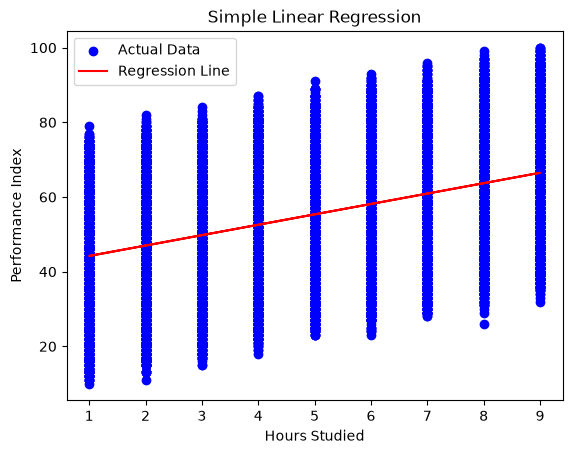

In [12]:
plt.scatter(X_simple, y, color='blue', label='Actual Data')
plt.plot(
    X_simple,
    simple_model.predict(X_simple),
    color='red',
    label='Regression Line'
)
plt.xlabel('Hours Studied')
plt.ylabel('Performance Index')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

In [13]:
print("MODEL COMPARISON")
print("Simple Linear Regression")
print("R2 Score:", r2_simple)
print("RMSE:", rmse_simple)
print("\nMultiple Linear Regression")
print("R2 Score:", r2_multiple)
print("RMSE:", rmse_multiple)
if r2_multiple > r2_simple:
    print("\nMultiple Linear Regression has a higher R2 score.")
elif r2_simple > r2_multiple:
    print("\nSimple Linear Regression has a higher R2 score.")
else:
    print("\nBoth models have the same R2 score.")

MODEL COMPARISON
Simple Linear Regression
R2 Score: 0.131604253859968
RMSE: 17.939190012852038

Multiple Linear Regression
R2 Score: 0.9877353198949831
RMSE: 2.1319258663050595

Multiple Linear Regression has a higher R2 score.
